# Final model - M9 with plain concatenation - 20 iterations + DARNet-style tables and figures

**Model:** M9 (patch quality + spatial criticality alpha + frame quality + temporal Transformer + attribute-specific temporal criticality beta + learned Overall head, frozen ResNet-50 layer4 + layer2/3 features, 16 photometric descriptors) with the adaptive CNN/Transformer gate replaced by **plain concatenation** (code `S1T1M1P1`). Nothing else is run here: no other model, no ablations.

**Protocol (same as the main study and DARNet):** 20 iterations; iteration = one random seed = one random 720 / 80 / 200 train / validation / test split (seeds 0-9 are the same splits as before, seeds 10-19 are new); 40 epochs max, early stopping on validation SRCC; test set used once; SRCC, PLCC, KRCC, RMSE for all six scores; the 4-parameter logistic mapping is fitted on the validation set and applied unchanged to the test set.

## How to run (Kaggle)
1. Attach the same two datasets as for the earlier notebooks (colonoscopy videos + MOS file). **GPU on, Internet on** (pretrained ResNet-50, downloaded once).
2. Run all cells in order. Feature extraction takes about 10-15 min the first time, then 20 training runs of about 1 minute each. The run is **resumable** (continues from `runs.csv` if the session stops).
3. Cell 8 builds every table and figure. Download **`cvstqa_final_concat_20iter_results.zip`** from the output panel and send it back.

## What Cell 8 produces (the way the DARNet paper presents its results)
| DARNet paper | Here | File |
|---|---|---|
| Table I (mean ± std, overall) | overall quality + mean of six scores, mean ± std, median | `tables/table_I_overall.csv` |
| Table II (each distortion attribute) | six scores x SRCC/PLCC/KRCC/RMSE, with DARNet beside it | `tables/table_II_per_attribute.csv`, `table_II_compact.csv` |
| Fig. 5 MOS histograms | six histograms | `fig5_MOS_distributions` |
| Fig. 6 correlation matrix of the MOS | lower-triangular PLCC heat-map | `fig6_MOS_correlation_matrix` |
| Fig. 11 scatter plots | overall (one test set), all six scores, overall over all 20 test sets | `fig11_*` |
| Fig. 12 box plots of PLCC / SRCC | one box per quality dimension over the 20 iterations | `fig12_boxplot_PLCC_SRCC` |
| Fig. 13 per-patient PLCC / SRCC | overall quality per patient, mean over iterations | `fig13_per_patient_overall` |
| extra | ours vs DARNet bars; overall SRCC/PLCC per iteration | `fig_extra_*` |

Every figure is saved as **EPS at 600 dpi** (plus PNG 600 dpi and PDF), with **bold axis labels and bold tick labels**. Also written: `README_final_results.md` (mean ± std, number of iterations better than DARNet, signed-rank p-values), `per_iteration_all_scores.csv`, `per_patient_overall.csv`, `mos_correlation_matrix_plcc.csv`.

**Check before using Fig. 13:** patients are identified by the file-name prefix (`PATIENT_REGEX` in Cell 1). Cell 8 prints how many patient groups it found; DARNet's dataset has 40 patients. If the number is very different, the prefix is not the patient ID - fix the regex (or load a real mapping) and re-run Cell 8 only.

In [1]:
# ============ CELL 1 — imports & configuration (ablation study 2: the FINAL model = M9 with plain concatenation instead of the adaptive gate) ============
import os, gc, json, math, random, time, copy, re, warnings, shutil, zipfile, platform, itertools, sys
from pathlib import Path
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from scipy.stats import pearsonr, spearmanr, kendalltau, wilcoxon
from scipy.optimize import curve_fit
import matplotlib
if "ipykernel" not in sys.modules: matplotlib.use("Agg")
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
cv2.setNumThreads(1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU")
if DEVICE.type == "cpu": print("WARNING: no GPU. Turn on a GPU (Kaggle: Settings -> Accelerator) and Internet (needed once for the pretrained ResNet-50).")

# ---------------- paths ----------------
INPUT = Path(os.environ.get("CVSTQA_INPUT", "/kaggle/input"))
WORK  = Path(os.environ.get("CVSTQA_WORK", "/kaggle/working")); WORK.mkdir(parents=True, exist_ok=True)
CACHE_MAIN = Path(os.environ.get("CVSTQA_CACHE_MAIN", "/tmp/cvstqa_cache"))          # cache of the M0-M13 notebook: reused if it is complete (same session)
CACHE = Path(os.environ.get("CVSTQA_CACHE", "/tmp/cvstqa_cache_ablation")); CACHE.mkdir(parents=True, exist_ok=True)   # otherwise the three needed features are extracted here (~10-15 min, ResNet-50 + photometric only)
SET_ID = os.environ.get("CVSTQA_SET", "1")                    # which of the four teammate sets this notebook is (1-4); only used in the output names
OUT   = WORK / "cvstqa_final_concat_20iter_results"
for sub in ["tables", "figures", "preds"]: (OUT / sub).mkdir(parents=True, exist_ok=True)
PRED_DIR, RUNS_CSV = OUT / "preds", OUT / "runs.csv"

# ---------------- protocol (same as the main study) ----------------
QUICK_TEST = os.environ.get("CVSTQA_SMOKE", "0") == "1"      # keep False for the real run
SEEDS      = list(range(20))          # 20 iterations; seed s -> split s (the SAME splits as the M0-M13 notebook)
EPOCHS, BATCH = 40, 32                # 720 train clips / 32 = 23 steps per epoch
EARLY_STOP, PATIENCE = True, 10
TEST_FRAC, VAL_FRAC = 0.20, 0.10
PRETRAINED, RANDOM_INIT = True, False
PATIENT_REGEX = r"^(\d+)-"            # used ONLY for the patient-independent Protocol B. CHECK that it really identifies the patient/exam (the dataset has ~40 exams): if the printout in Cell 2 shows far more groups than that, supply the true mapping (see Cell 2) before trusting Protocol B.
ATTRS = ["TSV", "B", "SR", "S", "U"]; TARGETS = ATTRS + ["O"]
SCORE_NAME = {"TSV": "TSV", "B": "B", "SR": "SR", "S": "S", "U": "U", "O": "Overall", "mean": "Mean(6)"}

# ---------------- what to run ----------------
FACTORS_ACTIVE = ["S", "T", "M", "P"]  # factorial ablation of the FINAL model (M9 with plain concatenation fusion; every cell keeps concatenation): S spatial attention | T temporal attention | M multi-stage features (layer2+3) | P photometric descriptors.
RUN_FACTORIAL   = True    # all 2^k on/off combinations of FACTORS_ACTIVE (k=4: 16 cells; S1T1M1P1 is the final model)
RUN_EXTRAS      = False   # the manual's other ablations (pooling variants, shared beta, T=8, patch grid, lambda, fusion) + controls
RUN_PROTOCOL_B  = False   # patient-independent split for a few key models
ONLY   = ["S1T1M1P1"]   # only the final model
ONLY_B = []   # no patient-independent split here
if QUICK_TEST:
    SEEDS, EPOCHS, TEST_FRAC, VAL_FRAC = [0, 1], 2, 0.30, 0.30
    PRETRAINED, RANDOM_INIT = False, True

# ---------------- fixed hyper-parameters (shared by every configuration) ----------------
HP = dict(D=256, DROPOUT=0.2, HEADS=4, SP_LAYERS=1, T_LAYERS=2, LR=5e-4, WD=1e-2, WARMUP=2, GRAD_CLIP=1.0,
          LAMBDA_RANK=0.1, RANK_MARGIN=0.05, LAMBDA_TEMP=0.5, TEMP_TAU=0.1)
NUM_FRAMES, IMAGE_SIZE, NUM_PATCHES = 16, 224, 49
CNN_DIM, MS_DIM, PH_DIM = 2048, 1536, 16

DARNET = {"TSV": (.910, .924, .744, .252), "B": (.798, .821, .607, .459), "SR": (.841, .855, .654, .343),
          "S": (.928, .933, .768, .276), "U": (.906, .914, .737, .283), "O": (.940, .943, .790, .332)}
DARNET["mean"] = tuple(round(float(np.mean([DARNET[t][i] for t in TARGETS])), 3) for i in range(4))

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
print(f"{len(SEEDS)} seeds | {EPOCHS} epochs | batch {BATCH} | factors {FACTORS_ACTIVE} | factorial {RUN_FACTORIAL} extras {RUN_EXTRAS} protocol-B {RUN_PROTOCOL_B} | quick-test {QUICK_TEST}")


torch 2.11.0+cu130 | device: cuda | Tesla T4
20 seeds | 40 epochs | batch 32 | factors ['S', 'T', 'M', 'P'] | factorial True extras False protocol-B False | quick-test False


In [2]:
# ============ CELL 2 — locate inputs & parse MOS (identical to the frozen-feature notebook) ============
print("Top-level input folders:")
for p in sorted(INPUT.iterdir()):
    print("  ", p)
    for q in sorted(p.iterdir())[:6]:
        print("      ", q.name)

# optional: show what the split dataset contains (not used for training here)
for p in INPUT.rglob("*"):
    if p.is_dir() and "split" in p.name.lower():
        print("\nSplit-like folder:", p)
        for q in sorted(p.rglob("*"))[:20]:
            if q.is_file(): print("    ", q.relative_to(p), f"({q.stat().st_size/1e3:.1f} KB)")

mos_file = next(INPUT.rglob("MOS.txt"))
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
all_videos = sorted(p for p in INPUT.rglob("*") if p.is_file() and p.suffix.lower() in VIDEO_EXTS)
print(f"\nMOS.txt: {mos_file}\nVideos found: {len(all_videos)}")

vmap = {}
for p in all_videos:
    vmap.setdefault(p.name.lower(), str(p)); vmap.setdefault(p.stem.lower(), str(p))

mos_df = pd.read_csv(mos_file, sep=None, engine="python", header=None,
                     names=["video_id"] + TARGETS, skipinitialspace=True)
mos_df["video_id"] = mos_df["video_id"].astype(str).str.strip()
for c in TARGETS:
    mos_df[c] = pd.to_numeric(mos_df[c], errors="coerce")
mos_df = mos_df.dropna(subset=TARGETS).reset_index(drop=True)          # drops a header row if present
mos_df["video_path"] = mos_df["video_id"].str.lower().map(vmap)
if mos_df["video_path"].isna().any():
    mos_df["video_path"] = mos_df["video_id"].map(lambda s: vmap.get(Path(s).stem.lower()))
assert mos_df["video_path"].notna().all(), mos_df[mos_df["video_path"].isna()].head()
print("Labelled & matched clips:", len(mos_df))
print(mos_df[TARGETS].describe().loc[["min", "max", "mean"]].round(3))

mos_df["patient"] = mos_df["video_id"].map(lambda s: (re.match(PATIENT_REGEX, s) or [None, s])[1])
print("Unique patient/group prefixes:", mos_df["patient"].nunique(), "(expected ~40 exams - if it is much larger, the prefix is NOT the patient: Protocol B would still leak. Fix PATIENT_REGEX in Cell 1, or load a real mapping here, e.g. mos_df['patient'] = mos_df['video_id'].map(dict(pd.read_csv('patients.csv').values)))")
Y = mos_df[TARGETS].values.astype(np.float32)          # [N, 6] raw MOS
N_VIDEOS = len(mos_df)
print(f"\nClips used: {N_VIDEOS} (the full dataset has 1,000)")
if N_VIDEOS != 1000 and not QUICK_TEST: print("WARNING: expected 1,000 labelled clips - check that both the video dataset and the MOS dataset are attached.")


Top-level input folders:
   /kaggle/input/datasets
       miruthulajmm

MOS.txt: /kaggle/input/datasets/miruthulajmm/vqa-mos/MOS.txt
Videos found: 1000
Labelled & matched clips: 1000
        TSV      B     SR     S      U      O
min   0.000  0.000  0.100  0.00  0.000  1.000
max   3.000  3.000  3.000  3.00  3.000  5.000
mean  1.738  1.617  1.619  1.55  1.722  3.075
Unique patient/group prefixes: 72 (expected ~40 exams - if it is much larger, the prefix is NOT the patient: Protocol B would still leak. Fix PATIENT_REGEX in Cell 1, or load a real mapping here, e.g. mos_df['patient'] = mos_df['video_id'].map(dict(pd.read_csv('patients.csv').values)))

Clips used: 1000 (the full dataset has 1,000)


In [3]:
# ============ CELL 3 — features needed by M9 only: ResNet-50 layer4 (l4), layer2+3 (ms), photometric descriptors (ph). Reuses the cache of the M0-M13 notebook if it is complete; otherwise extracts (one pass, resumable) ============
def photometric(fr):
    g = cv2.cvtColor(fr, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    hsv = cv2.cvtColor(fr, cv2.COLOR_RGB2HSV); S = hsv[..., 1].astype(np.float32) / 255.0; V = hsv[..., 2].astype(np.float32) / 255.0
    R, Gc, Bc = [fr[..., i].astype(np.float32) for i in range(3)]
    rg, yb = R - Gc, 0.5 * (R + Gc) - Bc
    colorful = np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2)
    lap = cv2.Laplacian(g, cv2.CV_32F); gx = cv2.Sobel(g, cv2.CV_32F, 1, 0); gy = cv2.Sobel(g, cv2.CV_32F, 0, 1)
    edges = cv2.Canny((g * 255).astype(np.uint8), 50, 150).mean() / 255.0
    noise = np.median(np.abs(g - cv2.GaussianBlur(g, (3, 3), 0))) / 0.6745
    hist = np.histogram(g, bins=32, range=(0, 1))[0].astype(np.float32); hist /= hist.sum() + 1e-8
    p5, p95 = np.percentile(g, [5, 95])
    return np.array([g.mean(), g.std(), p5, p95, (g < 0.1).mean(), (g > 0.9).mean(), ((V > 0.94) & (S < 0.25)).mean(),
                     S.mean(), S.std(), colorful / 100.0, np.log1p(lap.var() * 1e3), np.sqrt(gx ** 2 + gy ** 2).mean(), edges, noise,
                     (R / (Gc + 1.0)).mean(), -(hist * np.log(hist + 1e-8)).sum()], np.float32)

SHAPES = {"l4": ((N_VIDEOS, NUM_FRAMES, NUM_PATCHES, CNN_DIM), np.float16), "ms": ((N_VIDEOS, NUM_FRAMES, NUM_PATCHES, MS_DIM), np.float16), "ph": ((N_VIDEOS, NUM_FRAMES, PH_DIM), np.float32)}
FEATS = list(SHAPES)
def _complete(d, need_done_file="done.npy"):
    try:
        if not (d / need_done_file).exists() or not np.load(d / need_done_file).all(): return False
        if json.load(open(d / "cache_meta.json")).get("n") != N_VIDEOS: return False
        return all((d / f"{k}.npy").exists() and tuple(np.load(d / f"{k}.npy", mmap_mode="r").shape) == SHAPES[k][0] for k in FEATS)
    except Exception: return False

class VideoLite(Dataset):
    def __init__(self, paths, order): self.paths, self.order = paths, order
    def __len__(self): return len(self.order)
    def _rd(self, cap, last):
        ok, fr = cap.read()
        if ok: return cv2.resize(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), (IMAGE_SIZE, IMAGE_SIZE))
        return last if last is not None else np.zeros((IMAGE_SIZE, IMAGE_SIZE, 3), np.uint8)
    def __getitem__(self, k):
        i = int(self.order[k]); cap = cv2.VideoCapture(self.paths[i]); n = max(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), 1)
        frames, last = [], None
        for f in np.linspace(0, n - 1, NUM_FRAMES).astype(int):                                  # 16 uniformly sampled frames (identical to the main notebook)
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(f)); last = self._rd(cap, last); frames.append(last)
        cap.release()
        return torch.from_numpy(np.stack(frames)), torch.from_numpy(np.stack([photometric(f) for f in frames])), i

def resnet_stages(m, x):
    x = m.maxpool(m.relu(m.bn1(m.conv1(x)))); x = m.layer1(x); f2 = m.layer2(x); f3 = m.layer3(f2); f4 = m.layer4(f3); return f2, f3, f4

CACHE_USE = CACHE_MAIN if (not RANDOM_INIT and _complete(CACHE_MAIN)) else CACHE
if CACHE_USE == CACHE_MAIN: print(f"Reusing the complete feature cache of the M0-M13 notebook: {CACHE_MAIN}")
else:
    sig = {"feats": FEATS, "n": N_VIDEOS, "random_init": RANDOM_INIT, "ids": list(mos_df["video_id"][:5])}
    META, DONE = CACHE / "cache_meta.json", CACHE / "done.npy"
    fresh = not (META.exists() and json.load(open(META)) == sig and DONE.exists() and all((CACHE / f"{k}.npy").exists() for k in FEATS))
    mm = {k: np.lib.format.open_memmap(CACHE / f"{k}.npy", mode=("w+" if fresh else "r+"), dtype=SHAPES[k][1], shape=SHAPES[k][0]) for k in FEATS}
    done = np.zeros(N_VIDEOS, bool) if fresh else np.load(DONE); json.dump(sig, open(META, "w"))
    todo = np.where(~done)[0]; print(f"Extracting into {CACHE} | already cached {int(done.sum())}/{N_VIDEOS} | to do {len(todo)}")
    if len(todo):
        # pretrained ImageNet weights: from an attached file (works with Internet OFF) or downloaded (needs Internet ON). File name: resnet50-11ad3fb6.pth (= torchvision ResNet50_Weights.DEFAULT)
        _wf = next(iter(INPUT.rglob("resnet50-11ad3fb6.pth")), None) if INPUT.exists() else None
        if _wf is not None and PRETRAINED:
            rn = models.resnet50(weights=None); rn.load_state_dict(torch.load(_wf, map_location="cpu")); print("  loaded ResNet-50 weights from", _wf)
        else:
            try: rn = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if PRETRAINED else None)
            except Exception as e: raise SystemExit("Cannot download the ResNet-50 weights (Internet is OFF). Fix: Notebook settings -> Internet ON (the Kaggle account must be phone-verified), OR attach a dataset that contains resnet50-11ad3fb6.pth and re-run this cell. (" + type(e).__name__ + ")")
        rn = rn.to(DEVICE).eval()
        imean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1); istd = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
        dl = DataLoader(VideoLite(mos_df["video_path"].tolist(), todo), batch_size=4, num_workers=0 if QUICK_TEST else 2, pin_memory=(DEVICE.type == "cuda"))
        amp = dict(device_type=DEVICE.type, dtype=torch.float16, enabled=(DEVICE.type == "cuda")); t0 = time.time()
        def to_seq(t, b, d): return t.flatten(2).transpose(1, 2).reshape(b, NUM_FRAMES, NUM_PATCHES, d)
        with torch.inference_mode():
            for bi, (fr, ph, ids) in enumerate(dl):
                b, ii = fr.shape[0], ids.numpy()
                x = fr.to(DEVICE).view(b * NUM_FRAMES, IMAGE_SIZE, IMAGE_SIZE, 3).permute(0, 3, 1, 2).float() / 255.0
                with torch.autocast(**amp): f2, f3, f4 = resnet_stages(rn, (x - imean) / istd)
                mm["l4"][ii] = to_seq(f4.float(), b, CNN_DIM).half().cpu().numpy()
                mm["ms"][ii] = to_seq(torch.cat([F.adaptive_avg_pool2d(f2.float(), 7), F.adaptive_avg_pool2d(f3.float(), 7)], 1), b, MS_DIM).half().cpu().numpy()
                mm["ph"][ii] = ph.numpy(); done[ii] = True
                if bi % 25 == 0:
                    for v in mm.values(): v.flush()
                    np.save(DONE, done); print(f"  {int(done.sum())}/{N_VIDEOS} cached | {time.time()-t0:.0f}s")
        for v in mm.values(): v.flush()
        np.save(DONE, done); del rn
    assert done.all(), "Some videos failed to cache"
    del mm; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
print("Feature cache ready:", CACHE_USE)


Extracting into /tmp/cvstqa_cache_ablation | already cached 0/1000 | to do 1000
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 243MB/s]


  4/1000 cached | 23s
  104/1000 cached | 205s
  204/1000 cached | 403s
  304/1000 cached | 589s
  404/1000 cached | 779s
  504/1000 cached | 963s
  604/1000 cached | 1152s
  704/1000 cached | 1342s
  804/1000 cached | 1537s
  904/1000 cached | 1724s
Feature cache ready: /tmp/cvstqa_cache_ablation


In [4]:
# ============ CELL 4 — load the cached features (GPU if they fit) ============
STORE = {}
def _fits(nbytes):
    if DEVICE.type != "cuda": return False
    return nbytes < torch.cuda.mem_get_info()[0] - 5.5e9          # keep ~5.5 GB headroom for training
def load_big(name):
    arr = np.load(CACHE_USE / f"{name}.npy", mmap_mode="r"); nb = arr.size * arr.dtype.itemsize
    if _fits(nb):
        t = torch.empty(arr.shape, dtype=torch.float16, device=DEVICE)
        for i in range(0, len(arr), 50): t[i:i + 50] = torch.from_numpy(np.ascontiguousarray(arr[i:i + 50])).to(DEVICE)
        where = "GPU"
    else: t = torch.from_numpy(np.ascontiguousarray(arr)); where = "CPU RAM"
    print(f"  {name:3s} {tuple(arr.shape)} {nb/1e9:.2f} GB -> {where}"); return t
for k in ["l4", "ms"]:
    STORE[f"p_{k}"] = load_big(k)
    STORE[f"g_{k}"] = torch.cat([STORE[f"p_{k}"][i:i + 50].to(DEVICE).float().mean(2).half() for i in range(0, len(STORE[f"p_{k}"]), 50)])     # per-frame global feature = mean of the 49 patches
STORE["ph"] = torch.from_numpy(np.load(CACHE_USE / "ph.npy")).to(DEVICE)
Y = mos_df[TARGETS].values.astype(np.float32)
PH_PERM = torch.from_numpy(np.random.default_rng(12345).permutation(N_VIDEOS))      # fixed permutation for the "photometric shuffled" control
print("loaded:", {k: tuple(v.shape) for k, v in STORE.items()})
def take(name, idx):
    t = STORE[name]; return t[idx.to(t.device)].to(DEVICE, non_blocking=True).float()


  l4  (1000, 16, 49, 2048) 3.21 GB -> GPU
  ms  (1000, 16, 49, 1536) 2.41 GB -> GPU
loaded: {'p_l4': (1000, 16, 49, 2048), 'g_l4': (1000, 16, 2048), 'p_ms': (1000, 16, 49, 1536), 'g_ms': (1000, 16, 1536), 'ph': (1000, 16, 16)}


In [5]:
# ============ CELL 5 — the FINAL model (M9 with plain concatenation fusion) as a configurable network, and every ablation configuration ============
# M9 = patch tokens (ResNet-50 layer4 + layer2/3) -> per-patch attribute quality q and spatial criticality alpha -> frame quality Q_t
#      -> temporal Transformer -> attribute-specific temporal criticality beta -> video attribute scores (+ global residual) -> learned Overall head; photometric descriptors added to the frame context.
BASE = dict(use_patches=True, temporal="transformer", spatial_pool="attn", temporal_pool="attn", temp_loss=False, global_resid=True,
            ms=True, ph=True, grid=7, stride=1, fusion="concat", lam_rank=None, lam_temp=None, rank_overall_only=False, ph_shuffle=False)
def V(**kw):
    d = dict(BASE); d.update(kw); return d

FACTOR_NAME = {"S": "spatial attention (alpha)", "T": "temporal attention (beta)", "M": "multi-stage features (layer2+3)", "P": "photometric descriptors", "C": "temporal-consistency loss"}
def cell_cfg(bits):                       # bits: dict factor -> 0/1
    return V(spatial_pool="attn" if bits.get("S", 1) else "avg", temporal_pool="attn" if bits.get("T", 1) else "mean",
             ms=bool(bits.get("M", 1)), ph=bool(bits.get("P", 1)), temp_loss=bool(bits.get("C", 0)))
def cell_name(bits): return "".join(f"{f}{int(bits[f])}" for f in FACTORS_ACTIVE)
FULL_BITS = {f: (0 if f == "C" else 1) for f in FACTORS_ACTIVE}; FULL = cell_name(FULL_BITS)
ALIAS = {"S1T1M1P1": "FINAL = M9 + plain concatenation"}

VARIANTS, GROUP, DESC = {}, {}, {}
def add(name, cfg, group, desc): VARIANTS[name], GROUP[name], DESC[name] = cfg, group, desc
for combo in itertools.product([1, 0], repeat=len(FACTORS_ACTIVE)):                       # 2^k cells, full model first
    bits = dict(zip(FACTORS_ACTIVE, combo)); nm = cell_name(bits)
    add(nm, cell_cfg(bits), "factorial", ALIAS.get(nm, "") + " | " + ", ".join(f"{'+' if b else '-'}{f}" for f, b in bits.items()))
EXTRA = {                                   # the manual's other ablations (sections 8-10, 20, 29-33) and controls; each differs from the full model in ONE thing
    "A2_spatial_max":       (V(spatial_pool="max"),            "manual S31: spatial pooling = max over patches (instead of learned attention)"),
    "A3_temporal_max":      (V(temporal_pool="max"),           "manual S32: temporal pooling = max over frames"),
    "A4_shared_beta":       (V(temporal_pool="attn_shared"),   "manual S33: ONE temporal attention shared by all five attributes"),
    "A5_T8":                (V(stride=2),                      "manual S30: T = 8 frames (every 2nd cached frame); T = 24/32 need a re-extraction"),
    "A6_grid4":             (V(grid=4),                        "manual S29 (proxy): 7x7 grid average-pooled to 4x4 (larger patches)"),
    "A6_grid3":             (V(grid=3),                        "manual S29 (proxy): 3x3 grid"),
    "A6_grid2":             (V(grid=2),                        "manual S29 (proxy): 2x2 grid"),
    "A8_gate_restored":     (V(fusion="gate"),                 "manual S10: the adaptive CNN-Transformer gate restored instead of plain concatenation (= the previous M9)"),
    "A8_cnn_only":          (V(fusion="cnn"),                  "manual S9-10: no spatial contextual Transformer branch (CNN tokens only)"),
    "A8_transformer_only":  (V(fusion="trans"),                "manual S9-10: Transformer branch only"),
    "A9_rank0":             (V(lam_rank=0.0),                  "manual S19-20: no ranking loss"),
    "A9_rank0.05":          (V(lam_rank=0.05),                 "manual S20: lambda_r = 0.05"),
    "A9_rank0.2":           (V(lam_rank=0.2),                  "manual S20: lambda_r = 0.2"),
    "A9_rank0.5":           (V(lam_rank=0.5),                  "manual S20: lambda_r = 0.5"),
    "A9_rank_overall_only": (V(rank_overall_only=True),        "manual S19: ranking loss on the Overall score only (default: all six scores)"),
    "A9_consistency_0.05":  (V(temp_loss=True, lam_temp=0.05), "manual S18/S20: temporal-consistency loss with the manual's lambda_t = 0.05"),
    "A9_consistency_0.5":   (V(temp_loss=True, lam_temp=0.5),  "temporal-consistency loss with lambda_t = 0.5 (the value used for M6)"),
    "X_no_temporal_enc":    (V(temporal="none"),               "no temporal Transformer (beta then acts on frame features directly)"),
    "CTRL_ph_shuffled":     (V(ph_shuffle=True),               "control: photometric vectors shuffled across clips (same parameters, no real information)"),
}
for k, (c, d) in EXTRA.items(): add(k, c, "extra", d)
PROTO_B_MODELS = [FULL]      # patient-independent split: only the final model
PROTO_B_MODELS = list(dict.fromkeys(PROTO_B_MODELS))

def runs_for(protocol):
    names = []
    if protocol == "A":
        if RUN_FACTORIAL: names += [n for n in VARIANTS if GROUP[n] == "factorial"]
        if RUN_EXTRAS: names += [n for n in VARIANTS if GROUP[n] == "extra"]
    elif RUN_PROTOCOL_B: names = [n for n in PROTO_B_MODELS if n in VARIANTS]
    keep = ONLY if protocol == "A" else ONLY_B
    if keep is not None: names = [n for n in names if n in keep]
    return list(dict.fromkeys(names))

def mlp(i, h, o, p): return nn.Sequential(nn.Linear(i, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, o))
def tf_encoder(d, layers, p, heads):
    return nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 2 * d, p, activation="gelu", batch_first=True, norm_first=True), layers, enable_nested_tensor=False)

class Net(nn.Module):
    def __init__(self, cfg, hp, norm=None):
        super().__init__(); d, p, H = hp["D"], hp["DROPOUT"], hp["HEADS"]; self.cfg, self.hp = cfg, hp
        T, N = NUM_FRAMES // cfg["stride"], cfg["grid"] ** 2
        self.register_buffer("ph_mu", torch.zeros(PH_DIM)); self.register_buffer("ph_sd", torch.ones(PH_DIM))
        if norm is not None:
            for k, v in norm.items(): getattr(self, k).copy_(torch.as_tensor(v))
        gdim = CNN_DIM + (MS_DIM if cfg["ms"] else 0)
        self.gproj = nn.Sequential(nn.Dropout(p), nn.Linear(gdim, d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(p))
        if cfg["ph"]: self.phf, self.phc = mlp(PH_DIM, d, d, p), mlp(2 * PH_DIM, d, d, p)
        if cfg["temporal"] == "transformer":
            self.tpos = nn.Parameter(torch.zeros(1, T, d)); nn.init.trunc_normal_(self.tpos, std=0.02)
            self.tenc, self.tnorm = tf_encoder(d, hp["T_LAYERS"], p, H), nn.LayerNorm(d)
        if not cfg["use_patches"]:
            self.head = mlp(d, d, len(TARGETS), p); return
        self.pproj = nn.Sequential(nn.Dropout(p), nn.Linear(gdim, d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(p))
        self.ppos = nn.Parameter(torch.zeros(1, N, d)); nn.init.trunc_normal_(self.ppos, std=0.02)
        self.sp_enc = tf_encoder(d, hp["SP_LAYERS"], p, H)
        if cfg["fusion"] == "gate": self.gate = nn.Sequential(nn.Linear(2 * d, d), nn.Sigmoid())
        elif cfg["fusion"] == "concat": self.catf = nn.Sequential(nn.Linear(2 * d, d), nn.LayerNorm(d), nn.GELU())
        self.qh = nn.ModuleList([mlp(d, d // 2, 1, p) for _ in ATTRS])                              # local quality per attribute
        if cfg["spatial_pool"] == "attn": self.sh = nn.ModuleList([mlp(d, d // 2, 1, p) for _ in ATTRS])
        self.fuse = nn.Sequential(nn.Linear(d + len(ATTRS), d), nn.LayerNorm(d), nn.GELU())
        if cfg["temporal_pool"] == "attn": self.th = nn.ModuleList([mlp(d, d // 4, 1, p) for _ in ATTRS])
        elif cfg["temporal_pool"] == "attn_shared": self.th = nn.ModuleList([mlp(d, d // 4, 1, p)])
        if cfg["global_resid"]:
            self.gres = nn.Linear(d, len(ATTRS)); nn.init.zeros_(self.gres.weight); nn.init.zeros_(self.gres.bias)
        self.oh = mlp(len(ATTRS) + d, d, 1, p)

    def temporal(self, x): return self.tnorm(self.tenc(x + self.tpos)) if self.cfg["temporal"] == "transformer" else x

    def forward(self, B):
        cfg = self.cfg
        G = B["g_l4"] if not cfg["ms"] else torch.cat([B["g_l4"], B["g_ms"]], -1)
        g = self.gproj(G); pc = None
        if cfg["ph"]:
            ph = (B["ph"] - self.ph_mu) / self.ph_sd; g = g + self.phf(ph); pc = self.phc(torch.cat([ph.mean(1), ph.std(1)], -1))
        if not cfg["use_patches"]: return dict(pred=self.head(self.temporal(g).mean(1)), Q=None, alpha=None, beta=None, G=B["g_l4"])
        b, T = g.shape[:2]; N = cfg["grid"] ** 2
        P = B["p_l4"] if not cfg["ms"] else torch.cat([B["p_l4"], B["p_ms"]], -1)
        x = self.pproj(P.reshape(b * T, N, -1)); c = self.sp_enc(x + self.ppos)
        if cfg["fusion"] == "gate": gm = self.gate(torch.cat([x, c], -1)); f = gm * x + (1 - gm) * c          # adaptive CNN/Transformer fusion
        elif cfg["fusion"] == "concat": f = self.catf(torch.cat([x, c], -1))
        elif cfg["fusion"] == "cnn": f = x
        else: f = c
        q = torch.sigmoid(torch.cat([h(f) for h in self.qh], -1))                                              # [bT,N,5] local quality fields
        alpha = None
        if cfg["spatial_pool"] == "attn": alpha = torch.cat([h(f) for h in self.sh], -1).softmax(1); Qf = (alpha * q).sum(1)
        elif cfg["spatial_pool"] == "max": Qf = q.max(1).values
        else: Qf = q.mean(1)
        Q = Qf.view(b, T, len(ATTRS)); z = self.temporal(self.fuse(torch.cat([g, Q], -1))); beta = None
        if cfg["temporal_pool"] == "attn": beta = torch.cat([h(z) for h in self.th], -1).softmax(1); ya = (beta * Q).sum(1)
        elif cfg["temporal_pool"] == "attn_shared": beta = self.th[0](z).softmax(1).expand(-1, -1, len(ATTRS)); ya = (beta * Q).sum(1)
        elif cfg["temporal_pool"] == "max": ya = Q.max(1).values
        else: ya = Q.mean(1)
        zg = z.mean(1) + (pc if pc is not None else 0)
        if cfg["global_resid"]: ya = ya + self.gres(zg)
        yo = self.oh(torch.cat([ya, zg], -1))
        return dict(pred=torch.cat([ya, yo], -1), Q=Q, alpha=None if alpha is None else alpha.view(b, T, N, len(ATTRS)), beta=beta, G=B["g_l4"])

def count_params(name): return sum(p.numel() for p in Net(VARIANTS[name], HP).parameters() if p.requires_grad)
ALL_NAMES = list(dict.fromkeys(runs_for("A") + runs_for("B")))
PARAMS = {m: count_params(m) for m in ALL_NAMES}
print(f"{len([n for n in ALL_NAMES if n in runs_for('A')])} configurations for Protocol A, {len(runs_for('B'))} for Protocol B (patient-independent), {len(SEEDS)} seeds each")
print(pd.DataFrame({m: dict(params=PARAMS[m], group=GROUP[m], what=DESC[m]) for m in ALL_NAMES}).T.to_string())


1 configurations for Protocol A, 0 for Protocol B (patient-independent), 20 seeds each
           params      group                                               what
S1T1M1P1  4260245  factorial  FINAL = M9 + plain concatenation | +S, +T, +M, +P


In [6]:
# ============ CELL 6 — batches, losses, logistic mapping (reference-repo function), metrics, training, timing, splits ============
# ---------------- non-linear logistic mapping: the 4-parameter logistic of nithincbabu7/non-lin-fit-python (analysis.py), same call pattern ----------------
class NonLinearFit:
    """Re-implementation of NonLinearFit.four_param_logistic_QA from the reference repo:
       f(y) = (b1 - b2) / (1 + exp((b3 - y) / |b4|)) + b2,  fitted with scipy curve_fit(f, y=prediction, x=MOS), maxfev=10000.
       (only change: the exponent is clipped to +-60 so that np.exp cannot overflow.)"""
    def __init__(self): self.maxfev = 10000; self.params = None
    @staticmethod
    def four_param_logistic_QA(x, beta1, beta2, beta3, beta4):
        return ((beta1 - beta2) / (1 + np.exp(np.clip((beta3 - x) / (np.abs(beta4) + 1e-12), -60, 60)))) + beta2
    def fit(self, x, y, beta_init=None):          # x = target MOS, y = model prediction (same argument order as the reference code)
        if beta_init is None: beta_init = [np.min(x), np.max(x), np.mean(y), 1]
        self.params, _ = curve_fit(self.four_param_logistic_QA, y, x, p0=beta_init, maxfev=self.maxfev)
    def transform(self, y): return self.four_param_logistic_QA(y, *self.params)

def fit_mapping(mos, pred):
    """Fit the mapping on (pred -> mos). Tries the reference initial guess [min(MOS), max(MOS), mean(pred), 1] and, as a fallback, an increasing-curve guess;
    keeps the better fit, and only if it beats the identity mapping on the data it was fitted on. Returns (fit or None, ok, which_init)."""
    best = None
    for k, b0 in enumerate([[mos.min(), mos.max(), pred.mean(), 1.0], [mos.max(), mos.min(), pred.mean(), pred.std() / 4 + 1e-3]]):
        try:
            f = NonLinearFit(); f.fit(mos, pred, b0); err = np.mean((f.transform(pred) - mos) ** 2)
            if np.isfinite(err) and (best is None or err < best[0]): best = (err, f, k)
        except Exception: pass
    if best is None or best[0] > np.mean((pred - mos) ** 2): return None, False, -1
    return best[1], True, best[2]
def apply_mapping(f, pred): return pred if f is None else f.transform(pred)

def _corr(fn, a, b): return 0.0 if np.std(a) < 1e-9 or np.std(b) < 1e-9 else float(fn(a, b)[0])
def _rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def mean_srcc(y, p): return float(np.mean([_corr(spearmanr, y[:, j], p[:, j]) for j in range(y.shape[1])]))
METRICS = ["srcc", "krcc", "plcc_raw", "rmse_raw", "plcc_val", "rmse_val", "plcc_test", "rmse_test"]
def all_metrics(y_te, p_te, y_va, p_va):
    """per score: SRCC, KRCC, PLCC/RMSE raw, with the mapping fitted on VALIDATION (applied fixed to test) and fitted on TEST; the 4 logistic parameters of each fit; plus the six-score mean."""
    r = {}
    for j, t in enumerate(TARGETS):
        a, b = y_te[:, j], p_te[:, j]
        r[f"{t}_srcc"], r[f"{t}_krcc"] = _corr(spearmanr, a, b), _corr(kendalltau, a, b)
        r[f"{t}_plcc_raw"], r[f"{t}_rmse_raw"] = _corr(pearsonr, a, b), _rmse(a, b)
        for tag, (fx, fy) in {"val": (y_va[:, j], p_va[:, j]), "test": (a, b)}.items():
            f, ok, k = fit_mapping(fx, fy); m = apply_mapping(f, b)
            r[f"{t}_plcc_{tag}"], r[f"{t}_rmse_{tag}"], r[f"{t}_fitok_{tag}"], r[f"{t}_init_{tag}"] = _corr(pearsonr, a, m), _rmse(a, m), ok, k
            for q in range(4): r[f"{t}_{tag[0]}b{q+1}"] = float(f.params[q]) if f is not None else np.nan      # vb1..vb4 (val-fit), tb1..tb4 (test-fit)
    for m in METRICS: r[f"mean_{m}"] = float(np.mean([r[f"{t}_{m}"] for t in TARGETS]))
    return r
def make_split(seed):
    rng = np.random.default_rng(seed); n = N_VIDEOS; perm = rng.permutation(n)
    n_te = int(round(TEST_FRAC * n)); te, rest = perm[:n_te], perm[n_te:]
    n_va = int(round(VAL_FRAC * len(rest))); va, tr = rest[:n_va], rest[n_va:]
    assert not (set(tr) & set(te)) and not (set(va) & set(te)) and not (set(tr) & set(va))
    return np.sort(tr), np.sort(va), np.sort(te)

def make_split_group(seed):
    """Protocol B: patient-independent split. Whole groups (PATIENT_REGEX prefix) go to test, then validation, the rest is train. Sizes are approximately 200 / 80 / 720."""
    rng = np.random.default_rng(seed); pats = mos_df["patient"].values; order = rng.permutation(np.unique(pats)); n = len(pats)
    def take_groups(pool, target):
        chosen, c = [], 0
        for u in pool:
            if c >= target: break
            chosen.append(u); c += int((pats == u).sum())
        return chosen
    te_g = take_groups(order, int(round(TEST_FRAC * n))); rest_g = [u for u in order if u not in set(te_g)]
    n_rest = int((~np.isin(pats, te_g)).sum()); va_g = take_groups(rest_g, int(round(VAL_FRAC * n_rest)))
    te, va = np.where(np.isin(pats, te_g))[0], np.where(np.isin(pats, va_g))[0]; tr = np.where(~np.isin(pats, te_g + va_g))[0]
    assert not (set(tr) & set(te)) and not (set(va) & set(te)) and not (set(tr) & set(va)) and not (set(pats[tr]) & set(pats[te])) and not (set(pats[va]) & set(pats[te]))
    return np.sort(tr), np.sort(va), np.sort(te)
def split_for(protocol, seed): return make_split(seed) if protocol == "A" else make_split_group(seed)

# ---------------- batches ----------------
def pool_grid(x, g):                                  # [b,T,49,C] -> [b,T,g*g,C]  (average-pool the 7x7 grid to g x g)
    if g == 7: return x
    b, T, N, C = x.shape
    return F.adaptive_avg_pool2d(x.reshape(b * T, 7, 7, C).permute(0, 3, 1, 2), g).flatten(2).transpose(1, 2).reshape(b, T, g * g, C)
FRAME_PERM = torch.from_numpy(np.random.default_rng(777).permutation(NUM_FRAMES))
def get_batch(idx, cfg, shuffle_t=False):
    idx = torch.as_tensor(idx); s, g = cfg["stride"], cfg["grid"]
    fr = (lambda t: t[:, FRAME_PERM.to(t.device)][:, ::s]) if shuffle_t else (lambda t: t[:, ::s])
    B = {"g_l4": fr(take("g_l4", idx))}
    if cfg["ms"]: B["g_ms"] = fr(take("g_ms", idx))
    if cfg["use_patches"]:
        B["p_l4"] = pool_grid(fr(take("p_l4", idx)), g)
        if cfg["ms"]: B["p_ms"] = pool_grid(fr(take("p_ms", idx)), g)
    if cfg["ph"]: B["ph"] = fr(take("ph", PH_PERM[idx] if cfg["ph_shuffle"] else idx))
    return B

def compute_losses(out, y, cfg, hp):
    pred = out["pred"]; reg = F.mse_loss(pred, y)
    lam_r = hp["LAMBDA_RANK"] if cfg["lam_rank"] is None else cfg["lam_rank"]
    pr, yr = (pred[:, 5:], y[:, 5:]) if cfg["rank_overall_only"] else (pred, y)
    pdiff = pr[:, None] - pr[None]; tdiff = yr[:, None] - yr[None]; valid = (tdiff > 0.05).float()
    rank = (valid * F.relu(hp["RANK_MARGIN"] - pdiff)).sum() / (valid.sum() + 1e-6)
    loss = reg + lam_r * rank
    if cfg["temp_loss"] and out["Q"] is not None:
        Gn = F.normalize(out["G"], dim=-1); dist = 1 - (Gn[:, 1:] * Gn[:, :-1]).sum(-1); wt = torch.exp(-dist / hp["TEMP_TAU"]).detach()
        lam_t = hp["LAMBDA_TEMP"] if cfg["lam_temp"] is None else cfg["lam_temp"]
        loss = loss + lam_t * (wt * (out["Q"][:, 1:] - out["Q"][:, :-1]).pow(2).sum(-1)).mean()
    return loss

def _sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
@torch.no_grad()
def predict(model, idx, lo, hi, cfg, bs=64, shuffle_t=False):
    model.eval(); ps = []
    for i in range(0, len(idx), bs): ps.append(model(get_batch(torch.as_tensor(idx[i:i + bs]), cfg, shuffle_t))["pred"].float().cpu())
    return torch.cat(ps).numpy() * (hi - lo) + lo                 # back to the original MOS scale

@torch.no_grad()
def attn_stats(model, idx, cfg, bs=64):
    """Attention-collapse monitors of the manual (S39.3, S39.4) and the attribute-specificity check (S33): normalised entropy of alpha and beta (1 = uniform, 0 = one patch/frame) and the mean pairwise L1/2 distance between the five attribute-specific beta curves."""
    model.eval(); ea, eb, bd = [], [], []
    for i in range(0, len(idx), bs):
        o = model(get_batch(torch.as_tensor(idx[i:i + bs]), cfg))
        if o["alpha"] is not None: a = o["alpha"]; ea.append((-(a * (a + 1e-9).log()).sum(2) / math.log(a.shape[2])).mean().item())
        if o["beta"] is not None:
            b_ = o["beta"]; eb.append((-(b_ * (b_ + 1e-9).log()).sum(1) / math.log(b_.shape[1])).mean().item())
            bd.append(np.mean([0.5 * (b_[:, :, p] - b_[:, :, q]).abs().sum(1).mean().item() for p, q in itertools.combinations(range(5), 2)]))
    nan = float("nan"); return dict(ent_alpha=float(np.mean(ea)) if ea else nan, ent_beta=float(np.mean(eb)) if eb else nan, beta_attr_diff=float(np.mean(bd)) if bd else nan)

def make_norm(tr):
    ph = STORE["ph"][torch.as_tensor(tr).to(STORE["ph"].device)].reshape(-1, PH_DIM); return {"ph_mu": ph.mean(0).cpu(), "ph_sd": (ph.std(0) + 1e-6).cpu()}

def train_member(cfg, hp, tr, va, seed, lo, hi, Ys, norm):
    seed_everything(seed); model = Net(cfg, hp, norm).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["LR"], weight_decay=hp["WD"]); W = hp["WARMUP"]
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / W if e < W else max(0.02, 0.5 * (1 + math.cos(math.pi * (e - W) / max(1, EPOCHS - W)))))
    best, best_state, best_ep, best_step, bad, steps, steps_ep1, ep = -9, None, 0, 0, 0, 0, 0, 0; tr_t = torch.as_tensor(tr)
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = tr_t[torch.randperm(len(tr_t))]; nb = 0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 4: continue
            loss = compute_losses(model(get_batch(idx, cfg)), Ys[idx.to(Ys.device)], cfg, hp)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), hp["GRAD_CLIP"]); opt.step(); nb += 1; steps += 1
        if ep == 1: steps_ep1 = nb
        sched.step(); vs = mean_srcc(Y[va], predict(model, va, lo, hi, cfg))
        if vs > best + 1e-4:
            best, best_ep, best_step, bad = vs, ep, steps, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if EARLY_STOP and bad >= PATIENCE: break
    model.load_state_dict(best_state); model.eval()
    return model, dict(best_epoch=best_ep, step_at_best=best_step, epochs_run=ep, steps_per_epoch=steps_ep1, total_steps=steps, best_val_srcc=best)

def run(name, protocol, split, seed):
    cfg, hp = VARIANTS[name], HP; tr, va, te = split
    lo, hi = Y[tr].min(0), Y[tr].max(0) + 1e-8; Ys = torch.from_numpy((Y - lo) / (hi - lo)).float().to(DEVICE)
    _sync(); t0 = time.time(); model, info = train_member(cfg, hp, tr, va, seed, lo, hi, Ys, make_norm(tr)); _sync(); t_train = time.time() - t0
    pv = predict(model, va, lo, hi, cfg)
    _sync(); t1 = time.time(); pt = predict(model, te, lo, hi, cfg); _sync(); t_test = time.time() - t1          # the test set is touched once, after training
    np.save(PRED_DIR / f"{protocol}_{name}_s{seed}_val.npy", pv); np.save(PRED_DIR / f"{protocol}_{name}_s{seed}_test.npy", pt)
    res = all_metrics(Y[te], pt, Y[va], pv); res.update(attn_stats(model, te, cfg) if cfg["use_patches"] else dict(ent_alpha=np.nan, ent_beta=np.nan, beta_attr_diff=np.nan))
    if name == FULL and protocol == "A":                                                     # does the full model use frame ORDER? (test frames shuffled; the model is not retrained)
        ps = predict(model, te, lo, hi, cfg, shuffle_t=True); res["shuf_O_srcc"] = _corr(spearmanr, Y[te][:, 5], ps[:, 5]); res["shuf_mean_srcc"] = mean_srcc(Y[te], ps)
    res.update(val_mean_srcc=mean_srcc(Y[va], pv), best_epoch=info["best_epoch"], step_at_best=info["step_at_best"], epochs_run=info["epochs_run"], steps_per_epoch=info["steps_per_epoch"],
               total_steps=info["total_steps"], train_time_s=t_train, test_time_s=t_test, test_ms_per_clip=1000 * t_test / len(te), n_params=PARAMS[name], n_train=len(tr), n_val=len(va), n_test=len(te))
    del model; gc.collect()
    return res
print("steps per epoch:", math.ceil(len(make_split(0)[0]) / BATCH), "| epochs (max):", EPOCHS, "| Protocol A split sizes (train/val/test):", [len(a) for a in make_split(0)],
      "| Protocol B:", [len(a) for a in make_split_group(0)] if RUN_PROTOCOL_B else "off")


steps per epoch: 23 | epochs (max): 40 | Protocol A split sizes (train/val/test): [720, 80, 200] | Protocol B: off


In [7]:
# ============ CELL 7 — RUN: every configuration x every seed (resumable; one row per run is appended to runs.csv) ============
# Protocol A = the random split used by DARNet / the main study (seed s -> split s). Protocol B = patient-independent split (key models only).
rows = pd.read_csv(RUNS_CSV).to_dict("records") if RUNS_CSV.exists() else []
done_keys = {(r["protocol"], int(r["seed"]), r["model"]) for r in rows}
plan = [(p, s, m) for p in (["A"] + (["B"] if RUN_PROTOCOL_B else [])) for s in SEEDS for m in runs_for(p)]
print(f"{len([k for k in plan if k in done_keys])} of {len(plan)} runs already done")
t_all = time.time()
def seed_table(protocol, seed):
    d = pd.DataFrame([r for r in rows if r["protocol"] == protocol and int(r["seed"]) == seed and r["model"] in set(runs_for(protocol))])
    if not len(d): return
    t = pd.DataFrame({"model": d["model"]})
    for s in TARGETS: t[f"SRCC {SCORE_NAME[s]}"] = d[f"{s}_srcc"].round(4)
    t["Mean6"] = d["mean_srcc"].round(4); t["O PLCC"] = d["O_plcc_val"].round(4); t["O KRCC"] = d["O_krcc"].round(4); t["O RMSE"] = d["O_rmse_val"].round(4); t["train s"] = d["train_time_s"].round(1); t["best ep"] = d["best_epoch"].round(0)
    print(t.to_string(index=False))
for protocol in (["A"] + (["B"] if RUN_PROTOCOL_B else [])):
    for it, seed in enumerate(SEEDS):
        split = split_for(protocol, seed); did = False
        for name in runs_for(protocol):
            if (protocol, seed, name) in done_keys: continue
            r = run(name, protocol, split, seed); did = True
            r.update(seed=seed, model=name, protocol=protocol, group=GROUP[name], epochs_cfg=EPOCHS, early_stop=EARLY_STOP)
            rows.append(r); pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
            print(f"[{protocol} | iteration {it+1}/{len(SEEDS)} | seed {seed}] {name:22s} | train {r['train_time_s']:6.1f}s | test {r['test_ms_per_clip']:.2f} ms/clip | best epoch {r['best_epoch']:.0f}/{r['epochs_run']:.0f} | "
                  f"Overall SRCC {r['O_srcc']:.4f} PLCC {r['O_plcc_val']:.4f} KRCC {r['O_krcc']:.4f} RMSE {r['O_rmse_val']:.4f} | Mean(6) SRCC {r['mean_srcc']:.4f}")
            if DEVICE.type == "cuda": torch.cuda.empty_cache()
        if did: print(f"\n----- protocol {protocol}, seed {seed}: all configurations (val-fit mapping for PLCC/RMSE) -----"); seed_table(protocol, seed); print()
print(f"Finished. This session: {(time.time() - t_all) / 3600:.2f} h | runs.csv has {len(rows)} rows")


0 of 20 runs already done
[A | iteration 1/20 | seed 0] S1T1M1P1               | train   51.1s | test 1.42 ms/clip | best epoch 6/16 | Overall SRCC 0.9432 PLCC 0.9431 KRCC 0.7985 RMSE 0.3401 | Mean(6) SRCC 0.8760

----- protocol A, seed 0: all configurations (val-fit mapping for PLCC/RMSE) -----
   model  SRCC TSV  SRCC B  SRCC SR  SRCC S  SRCC U  SRCC Overall  Mean6  O PLCC  O KRCC  O RMSE  train s  best ep
S1T1M1P1    0.8954  0.7993   0.8353  0.8956   0.887        0.9432  0.876  0.9431  0.7985  0.3401     51.1        6

[A | iteration 2/20 | seed 1] S1T1M1P1               | train   63.0s | test 1.51 ms/clip | best epoch 11/21 | Overall SRCC 0.9477 PLCC 0.9456 KRCC 0.8002 RMSE 0.3482 | Mean(6) SRCC 0.8773

----- protocol A, seed 1: all configurations (val-fit mapping for PLCC/RMSE) -----
   model  SRCC TSV  SRCC B  SRCC SR  SRCC S  SRCC U  SRCC Overall  Mean6  O PLCC  O KRCC  O RMSE  train s  best ep
S1T1M1P1    0.9173  0.7203   0.8178  0.9352  0.9255        0.9477 0.8773  0.9456  0.8

final model S1T1M1P1 (FINAL = M9 + plain concatenation): 20 iterations -> seeds [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

TABLE I - overall quality (mean±std over iterations; PLCC/RMSE with validation-fitted logistic mapping)
                                        Methods        SRCC        PLCC        KRCC        RMSE
                          DARNet (paper, mean)        0.94       0.943        0.79       0.332
Ours: M9 + plain concatenation (20 iterations) 0.938±0.009 0.938±0.007 0.783±0.016 0.358±0.016
                                  Ours: median       0.939       0.938       0.783       0.360
                  Ours: Mean of the six scores 0.878±0.009 0.886±0.008 0.704±0.011 0.352±0.010
                DARNet: Mean of the six scores       0.887       0.898       0.717       0.324

TABLE II - each quality dimension
              DARNet         Ours
TSV     SRCC   0.91  0.897±0.015
        PLCC  0.924  0.912±0.011
        KRCC  0.744  0.727±0.020
     

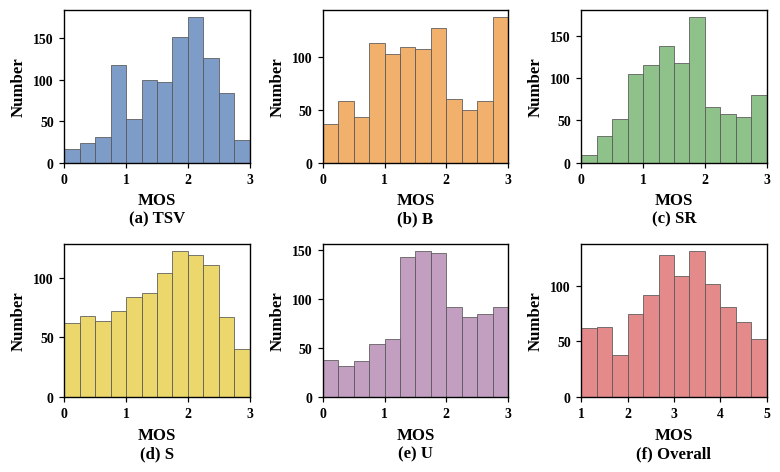

saved fig6_MOS_correlation_matrix.eps / .png / .pdf  (600 dpi)


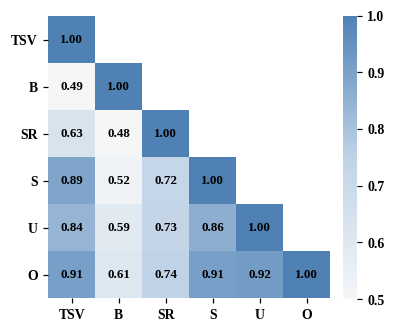

saved fig11_scatter_overall.eps / .png / .pdf  (600 dpi)


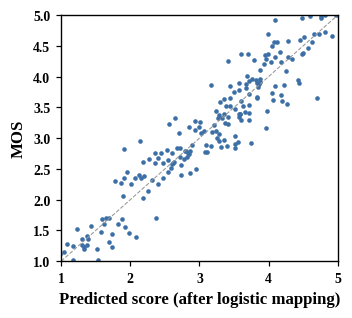

saved fig11_scatter_six_scores.eps / .png / .pdf  (600 dpi)


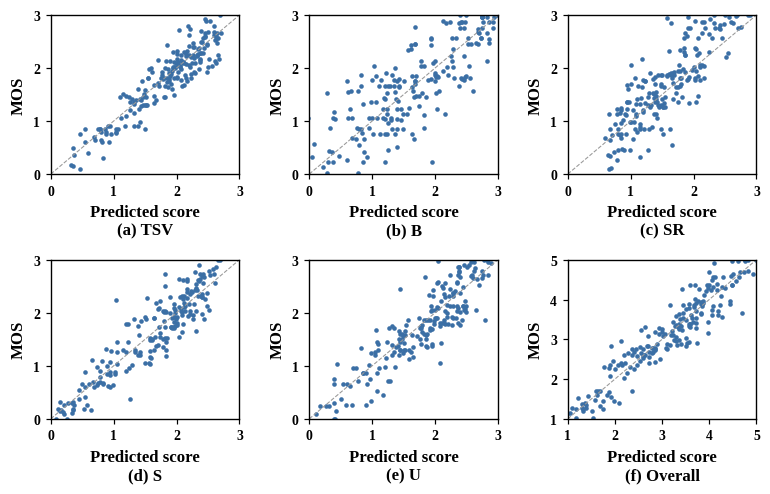

saved fig11_scatter_overall_all_iterations.eps / .png / .pdf  (600 dpi)


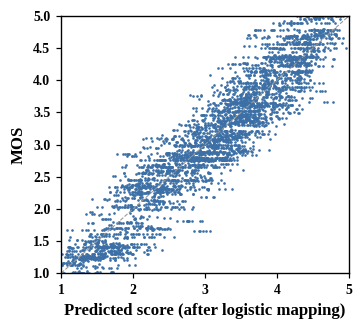

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig12_boxplot_PLCC_SRCC.eps / .png / .pdf  (600 dpi)


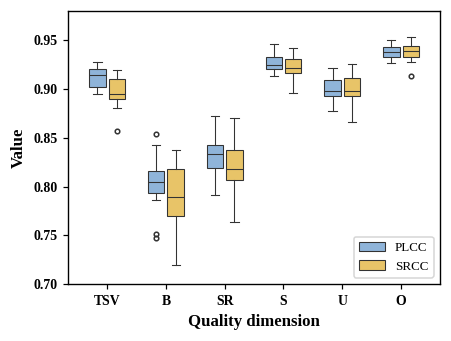


per-patient groups with usable test clips: 68 (the dataset has ~40 patients; if this number is very different, PATIENT_REGEX in Cell 1 does not identify the patient - fix it, then re-run this cell only)
saved fig13_per_patient_overall.eps / .png / .pdf  (600 dpi)


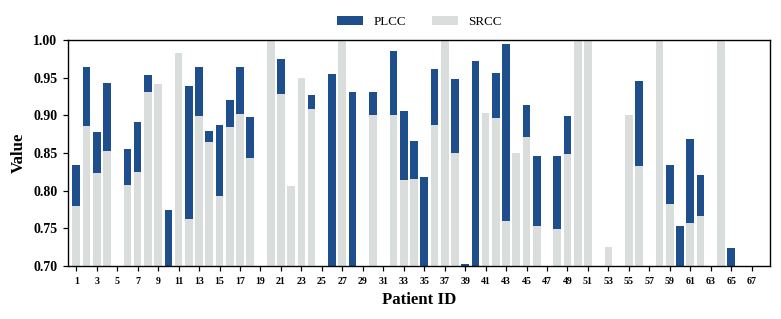

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig_extra_ours_vs_DARNet.eps / .png / .pdf  (600 dpi)


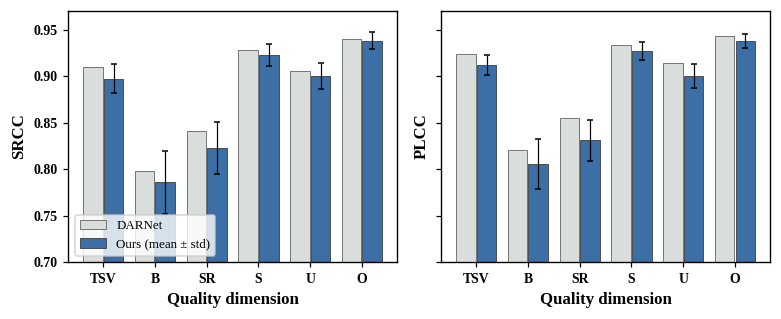

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved fig_extra_overall_per_iteration.eps / .png / .pdf  (600 dpi)


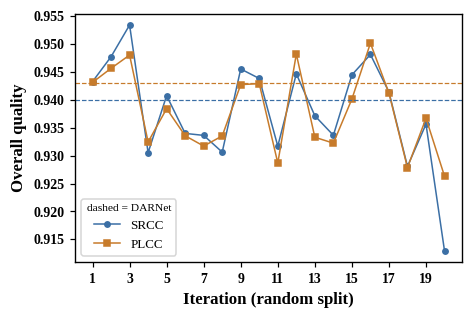


Files in figures/: ['fig11_scatter_overall.eps', 'fig11_scatter_overall_all_iterations.eps', 'fig11_scatter_six_scores.eps', 'fig12_boxplot_PLCC_SRCC.eps', 'fig13_per_patient_overall.eps', 'fig5_MOS_distributions.eps', 'fig6_MOS_correlation_matrix.eps', 'fig_extra_ours_vs_DARNet.eps', 'fig_extra_overall_per_iteration.eps']


In [10]:
# ============ CELL 8 — DARNet-style tables and figures for the FINAL model (M9 + plain concatenation), 20 iterations ============
# Reproduces the way the DARNet paper (IEEE TMI 2025) presents its results:
#   Table I (mean +- std, overall)        -> table_I_overall.csv
#   Table II (each distortion attribute)  -> table_II_per_attribute.csv
#   Fig. 5  MOS histograms                -> fig5_MOS_distributions
#   Fig. 6  MOS correlation matrix (PLCC) -> fig6_MOS_correlation_matrix
#   Fig. 11 scatter, prediction vs MOS    -> fig11_scatter_overall, fig11_scatter_six_scores
#   Fig. 12 box plots of PLCC / SRCC      -> fig12_boxplot_PLCC_SRCC (one box per quality dimension, over the 20 iterations)
#   Fig. 13 per-patient PLCC / SRCC       -> fig13_per_patient_overall
#   extras: ours-vs-DARNet bars, per-iteration curve
# Every figure is saved as EPS (600 dpi), plus PNG (600 dpi) and PDF.  All axis labels and tick labels are bold.
FIG = OUT / "figures"; TAB = OUT / "tables"; FIG.mkdir(exist_ok=True, parents=True); TAB.mkdir(exist_ok=True, parents=True)
DPI = 600
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"],
    "font.size": 10, "axes.labelsize": 11, "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.titlesize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.5, "axes.linewidth": 0.9,
    "ps.fonttype": 42, "pdf.fonttype": 42, "svg.fonttype": "none", "figure.dpi": 110, "savefig.dpi": DPI,
    "mathtext.default": "regular"})

def bold_axes(*axs):
    for ax in axs:
        for t in ax.get_xticklabels() + ax.get_yticklabels(): t.set_fontweight("bold")
        ax.xaxis.label.set_fontweight("bold"); ax.yaxis.label.set_fontweight("bold")
def save_fig(fig, name):
    for ax in fig.axes: bold_axes(ax)
    for ext in ("eps", "png", "pdf"):
        fig.savefig(FIG / f"{name}.{ext}", format=ext, dpi=DPI, bbox_inches="tight", facecolor="white")
    print(f"saved {name}.eps / .png / .pdf  (600 dpi)")
    if "ipykernel" in sys.modules: plt.show()
    plt.close(fig)

ORDER = ["TSV", "B", "SR", "S", "U", "O"]
NAME6 = {"TSV": "TSV", "B": "B", "SR": "SR", "S": "S", "U": "U", "O": "Overall"}
BLUE, BLUE2, YEL, GREY = "#3B6FA5", "#8FB4D9", "#E8C468", "#D9DEDC"
HIST_COL = ["#7D9CC7", "#F2B06D", "#8FC28A", "#EBD76B", "#C29FC1", "#E48A8A"]            # same colour order as DARNet Fig. 5

# ---------------- collect the 20 iterations of the final model ----------------
runs = pd.read_csv(RUNS_CSV); R = runs[(runs["protocol"] == "A") & (runs["model"] == FULL)].drop_duplicates("seed").sort_values("seed").reset_index(drop=True)
seeds_done = R["seed"].astype(int).tolist(); n_it = len(seeds_done)
print(f"final model {FULL} ({ALIAS.get(FULL, FULL)}): {n_it} iterations -> seeds {seeds_done}")
assert n_it >= 2, "run Cell 7 first"
MET = {"SRCC": "{t}_srcc", "PLCC": "{t}_plcc_val", "KRCC": "{t}_krcc", "RMSE": "{t}_rmse_val"}      # PLCC / RMSE after the logistic mapping fitted on the VALIDATION set (same as the DARNet protocol)
def col(t, m): return R[MET[m].format(t=t)].values.astype(float)
def ms(x, d=3): return f"{np.mean(x):.{d}f}±{np.std(x, ddof=1):.{d}f}"

# ---------------- predictions (original MOS scale) with the validation-fitted logistic mapping applied to the test set ----------------
PRED = {}            # seed -> dict(te=idx, y=[n,6] MOS, raw=[n,6], mapped=[n,6])
for s in seeds_done:
    tr_, va_, te_ = make_split(s); pt = np.load(PRED_DIR / f"A_{FULL}_s{s}_test.npy"); pv = np.load(PRED_DIR / f"A_{FULL}_s{s}_val.npy"); mp = np.zeros_like(pt)
    for j in range(6):
        f, ok, _ = fit_mapping(Y[va_][:, j], pv[:, j]); mp[:, j] = apply_mapping(f, pt[:, j])
    PRED[s] = dict(te=te_, y=Y[te_], raw=pt, mapped=mp)

# =====================================================================  TABLE I  (overall quality, mean +- std over iterations)
dn = DARNET
rowsI = []
for lab, t in [("Overall quality", "O")]:
    rowsI.append(dict(Methods="DARNet (paper, mean)", **{m: dn[t][i] for i, m in enumerate(["SRCC", "PLCC", "KRCC", "RMSE"])}))
    rowsI.append(dict(Methods=f"Ours: M9 + plain concatenation ({n_it} iterations)", **{m: ms(col(t, m)) for m in MET}))
    rowsI.append(dict(Methods="Ours: median", **{m: f"{np.median(col(t, m)):.3f}" for m in MET}))
rowsI.append(dict(Methods="Ours: Mean of the six scores", **{m: ms(np.mean([col(t, m) for t in ORDER], 0)) for m in MET}))
rowsI.append(dict(Methods="DARNet: Mean of the six scores", **{m: dn["mean"][i] for i, m in enumerate(["SRCC", "PLCC", "KRCC", "RMSE"])}))
T1 = pd.DataFrame(rowsI); T1.to_csv(TAB / "table_I_overall.csv", index=False); print("\nTABLE I - overall quality (mean±std over iterations; PLCC/RMSE with validation-fitted logistic mapping)\n", T1.to_string(index=False))

# =====================================================================  TABLE II (every distortion attribute)
rowsII = []
for t in ORDER:
    for i, m in enumerate(MET):
        x = col(t, m); d = dn[t][i]
        better = (x > d) if m != "RMSE" else (x < d)
        rowsII.append(dict(Score=NAME6[t], Metric=m, DARNet=d, Ours_mean=round(float(np.mean(x)), 4), Ours_std=round(float(np.std(x, ddof=1)), 4), Ours_median=round(float(np.median(x)), 4),
                           Ours_min=round(float(np.min(x)), 4), Ours_max=round(float(np.max(x)), 4), Delta_vs_DARNet=round(float(np.mean(x) - d), 4),
                           Iterations_better_than_DARNet=f"{int(better.sum())}/{n_it}"))
T2 = pd.DataFrame(rowsII); T2.to_csv(TAB / "table_II_per_attribute.csv", index=False)
w2 = {}
for t in ORDER:
    for i, m in enumerate(MET): w2[(NAME6[t], m)] = {"DARNet": dn[t][i], "Ours": ms(col(t, m))}
T2w = pd.DataFrame(w2).T; T2w.to_csv(TAB / "table_II_compact.csv"); print("\nTABLE II - each quality dimension\n", T2w.to_string())
pd.DataFrame({f"{NAME6[t]} {m}": col(t, m) for t in ORDER for m in MET}, index=pd.Index(seeds_done, name="iteration (seed)")).round(4).to_csv(TAB / "per_iteration_all_scores.csv")

# =====================================================================  readings: win counts and a signed-rank test against the DARNet mean
from scipy.stats import wilcoxon as _wx
lines = [f"# Final model ({ALIAS.get(FULL, FULL)}) - {n_it} iterations (random 720/80/200 splits, seeds {seeds_done[0]}..{seeds_done[-1]})", "",
         "Values are mean ± sample std over iterations. PLCC and RMSE use the 4-parameter logistic mapping fitted on the validation set and applied unchanged to the test set. The test set is used once per iteration.", "",
         "| Score | Metric | DARNet | Ours (mean ± std) | Δ | iterations better | Wilcoxon p (vs DARNet mean) |", "|---|---|---|---|---|---|---|"]
for t in ORDER:
    for i, m in enumerate(MET):
        x = col(t, m); d = dn[t][i]; better = (x > d) if m != "RMSE" else (x < d)
        try: p = _wx(x - d).pvalue
        except Exception: p = float("nan")
        lines.append(f"| {NAME6[t]} | {m} | {d:.3f} | {ms(x)} | {np.mean(x) - d:+.4f} | {int(better.sum())}/{n_it} | {p:.3f} |")
lines += ["", "The p-value is a one-sample signed-rank test of the per-iteration values against DARNet's reported mean (DARNet's per-split values are not published, so a paired test is not possible). Treat it as an indication, not a proof.",
          "", "Mean of the six scores: " + " | ".join(f"{m} {ms(np.mean([col(t, m) for t in ORDER], 0))} (DARNet {dn['mean'][i]:.3f})" for i, m in enumerate(MET))]
open(OUT / "README_final_results.md", "w").write("\n".join(lines)); print("\n" + "\n".join(lines[:4] + lines[-1:]))

# =====================================================================  Fig. 5  MOS distributions
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.4))
for k, (ax, t) in enumerate(zip(axs.ravel(), ORDER)):
    j = TARGETS.index(t); rng_ = (1, 5) if t == "O" else (0, 3); ax.hist(Y[:, j], bins=12, range=rng_, color=HIST_COL[k], edgecolor="#555555", linewidth=0.5)
    ax.set_xlabel(f"MOS\n({'abcdef'[k]}) {NAME6[t]}"); ax.set_ylabel("Number"); ax.set_xlim(*rng_); ax.set_xticks(range(rng_[0], rng_[1] + 1))
fig.tight_layout(); save_fig(fig, "fig5_MOS_distributions")

# =====================================================================  Fig. 6  correlation matrix between the six MOS (PLCC)
C = np.corrcoef(Y.T); pd.DataFrame(C, index=ORDER, columns=ORDER).round(3).to_csv(TAB / "mos_correlation_matrix_plcc.csv")
from matplotlib.colors import LinearSegmentedColormap
cm = LinearSegmentedColormap.from_list("db", ["#F4F6F8", "#BFD3E6", "#4F81B5"]); cm.set_bad("white")
M = np.ma.masked_where(np.triu(np.ones_like(C, bool), 1), C)
fig, ax = plt.subplots(figsize=(3.6, 3.2)); im = ax.imshow(M, cmap=cm, vmin=0.5, vmax=1.0)
for i in range(6):
    for j in range(i + 1): ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=8.5, fontweight="bold")
ax.set_xticks(range(6)); ax.set_xticklabels(ORDER); ax.set_yticks(range(6)); ax.set_yticklabels(ORDER)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.outline.set_visible(False)
for t_ in cb.ax.get_yticklabels(): t_.set_fontweight("bold")
fig.tight_layout(); save_fig(fig, "fig6_MOS_correlation_matrix")

# =====================================================================  Fig. 11  scatter of prediction vs MOS (test set of one iteration, like DARNet)
SC = seeds_done[0]; P = PRED[SC]
def scat(ax, j, lim, s=9):
    ax.scatter(P["mapped"][:, j], P["y"][:, j], s=s, color=BLUE, linewidths=0)
    ax.plot(lim, lim, color="#999999", lw=0.7, ls="--"); ax.set_xlim(*lim); ax.set_ylim(*lim)
fig, ax = plt.subplots(figsize=(3.3, 3.0)); scat(ax, 5, (1, 5)); ax.set_xlabel("Predicted score (after logistic mapping)"); ax.set_ylabel("MOS")
fig.tight_layout(); save_fig(fig, "fig11_scatter_overall")
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.6))
for k, (ax, t) in enumerate(zip(axs.ravel(), ORDER)):
    j = TARGETS.index(t); lim = (1, 5) if t == "O" else (0, 3); scat(ax, j, lim); ax.set_xlabel(f"Predicted score\n({'abcdef'[k]}) {NAME6[t]}"); ax.set_ylabel("MOS")
fig.tight_layout(); save_fig(fig, "fig11_scatter_six_scores")
fig, ax = plt.subplots(figsize=(3.4, 3.1))                     # all iterations pooled (every test clip of every iteration)
ax.scatter(np.concatenate([PRED[s]["mapped"][:, 5] for s in seeds_done]), np.concatenate([PRED[s]["y"][:, 5] for s in seeds_done]), s=3, color=BLUE, linewidths=0)
ax.plot((1, 5), (1, 5), color="#999999", lw=0.7, ls="--"); ax.set_xlim(1, 5); ax.set_ylim(1, 5); ax.set_xlabel("Predicted score (after logistic mapping)"); ax.set_ylabel("MOS")
fig.tight_layout(); save_fig(fig, "fig11_scatter_overall_all_iterations")

# =====================================================================  Fig. 12  box plots of PLCC / SRCC per quality dimension (over the iterations)
fig, ax = plt.subplots(figsize=(4.2, 3.2)); pos = np.arange(len(ORDER)); w = 0.33
bp1 = ax.boxplot([col(t, "PLCC") for t in ORDER], positions=pos - w / 2, widths=0.28, patch_artist=True, flierprops=dict(marker="o", markersize=3, markeredgecolor="#333333"))
bp2 = ax.boxplot([col(t, "SRCC") for t in ORDER], positions=pos + w / 2, widths=0.28, patch_artist=True, flierprops=dict(marker="o", markersize=3, markeredgecolor="#333333"))
for bp, c in ((bp1, BLUE2), (bp2, YEL)):
    for b in bp["boxes"]: b.set(facecolor=c, edgecolor="#333333", linewidth=0.7)
    for k in ("whiskers", "caps", "medians"):
        for e in bp[k]: e.set(color="#333333", linewidth=0.7)
ax.set_xticks(pos); ax.set_xticklabels(ORDER); ax.set_xlabel("Quality dimension"); ax.set_ylabel("Value"); ax.set_ylim(0.70, 0.98)
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["PLCC", "SRCC"], loc="lower right", frameon=True)
fig.tight_layout(); save_fig(fig, "fig12_boxplot_PLCC_SRCC")

# =====================================================================  Fig. 13  per-patient PLCC / SRCC on the overall quality (test clips grouped by patient, mean over iterations)
pat = mos_df["patient"].values; rows13 = []
for s in seeds_done:
    te_ = PRED[s]["te"]; yy, pp = PRED[s]["y"][:, 5], PRED[s]["mapped"][:, 5]
    for u in np.unique(pat[te_]):
        m_ = pat[te_] == u
        if m_.sum() >= 3 and np.std(yy[m_]) > 1e-9 and np.std(pp[m_]) > 1e-9:
            rows13.append(dict(patient=u, seed=s, n=int(m_.sum()), SRCC=float(spearmanr(yy[m_], pp[m_])[0]), PLCC=float(pearsonr(yy[m_], pp[m_])[0])))
PT = pd.DataFrame(rows13); PTm = PT.groupby("patient").agg(n_clips_mean=("n", "mean"), iterations=("seed", "count"), SRCC=("SRCC", "mean"), PLCC=("PLCC", "mean")).reset_index()
PTm["_k"] = pd.to_numeric(PTm["patient"], errors="coerce"); PTm = PTm.sort_values(["_k", "patient"]).drop(columns="_k").reset_index(drop=True); PTm.insert(0, "Patient ID", range(1, len(PTm) + 1))
PTm.round(4).to_csv(TAB / "per_patient_overall.csv", index=False)
print(f"\nper-patient groups with usable test clips: {len(PTm)} (the dataset has ~40 patients; if this number is very different, PATIENT_REGEX in Cell 1 does not identify the patient - fix it, then re-run this cell only)")
fig, ax = plt.subplots(figsize=(7.2, 3.0)); x = PTm["Patient ID"].values
ax.bar(x, PTm["PLCC"], width=0.75, color="#1F4E8C", label="PLCC"); ax.bar(x, PTm["SRCC"], width=0.75, color=GREY, label="SRCC")
ax.set_ylim(0.70, 1.0); ax.set_xlim(0.2, len(PTm) + 0.8); ax.set_xticks(x[::1] if len(x) <= 45 else x[::2]); ax.tick_params(axis="x", labelsize=6.5)
ax.set_xlabel("Patient ID"); ax.set_ylabel("Value"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.tight_layout(); save_fig(fig, "fig13_per_patient_overall")

# =====================================================================  extras: ours vs DARNet per score; per-iteration curve
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
for ax, m in zip(axs, ["SRCC", "PLCC"]):
    xs = np.arange(len(ORDER)); i = list(MET).index(m)
    ax.bar(xs - 0.2, [dn[t][i] for t in ORDER], 0.38, color=GREY, edgecolor="#555555", linewidth=0.5, label="DARNet")
    ax.bar(xs + 0.2, [np.mean(col(t, m)) for t in ORDER], 0.38, yerr=[np.std(col(t, m), ddof=1) for t in ORDER], capsize=2, color=BLUE, edgecolor="#333333", linewidth=0.5, error_kw=dict(lw=0.8), label="Ours (mean ± std)")
    ax.set_xticks(xs); ax.set_xticklabels(ORDER); ax.set_xlabel("Quality dimension"); ax.set_ylabel(m if m == "SRCC" else ""); ax.set_ylim(0.7, 0.97)
axs[0].legend(loc="lower left", frameon=True); axs[1].set_ylabel("PLCC"); fig.tight_layout(); save_fig(fig, "fig_extra_ours_vs_DARNet")
fig, ax = plt.subplots(figsize=(4.4, 3.0)); itn = np.arange(1, n_it + 1)
ax.plot(itn, col("O", "SRCC"), "-o", ms=3.5, lw=1, color=BLUE, label="SRCC"); ax.plot(itn, col("O", "PLCC"), "-s", ms=3.5, lw=1, color="#C77B2B", label="PLCC")
ax.axhline(dn["O"][0], color=BLUE, ls="--", lw=0.8); ax.axhline(dn["O"][1], color="#C77B2B", ls="--", lw=0.8)
ax.set_xlabel("Iteration (random split)"); ax.set_ylabel("Overall quality"); ax.set_xticks(itn[::2]); ax.legend(loc="lower left", frameon=True, title="dashed = DARNet", title_fontsize=7.5)
fig.tight_layout(); save_fig(fig, "fig_extra_overall_per_iteration")

# one-line check of what was written
print("\nFiles in figures/:", sorted(p.name for p in FIG.glob("*.eps")))


saved fig7_prediction_correlation_matrices_15_iterations.eps / .png / .pdf  (600 dpi)


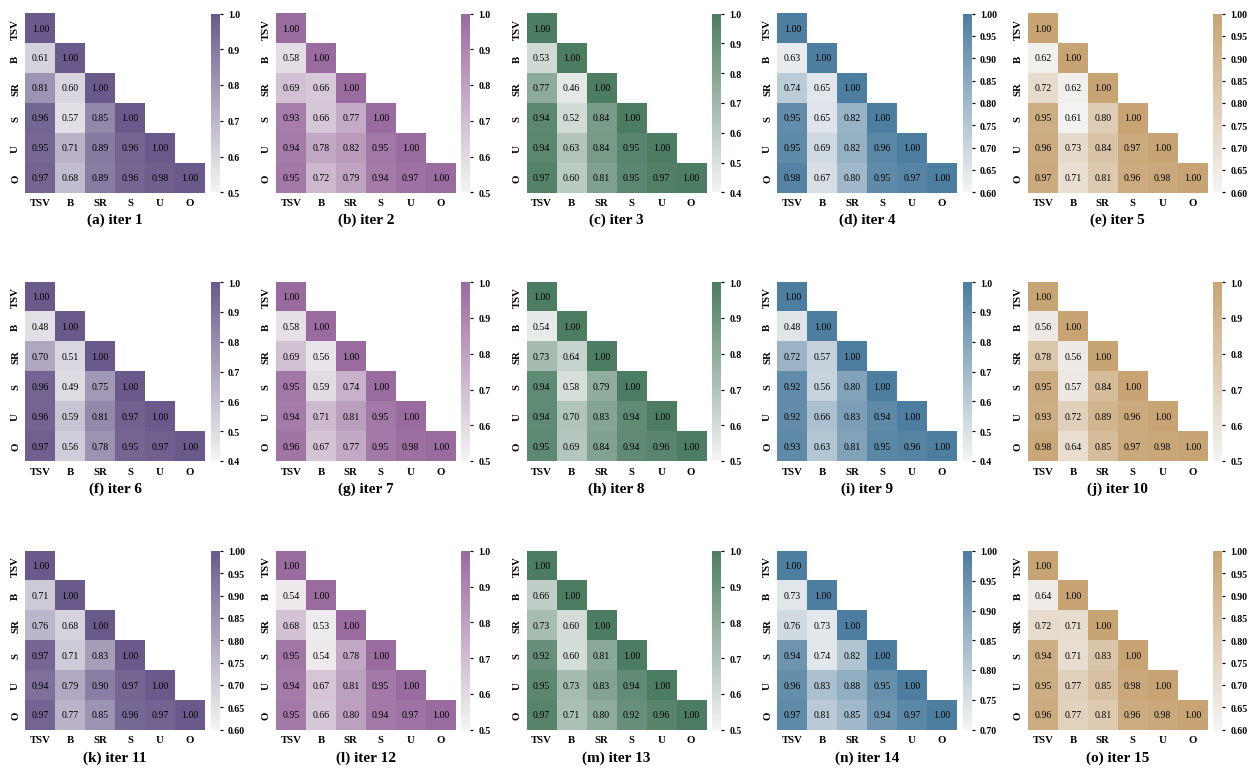

saved fig7_MOS_correlation_matrices_15_iterations.eps / .png / .pdf  (600 dpi)


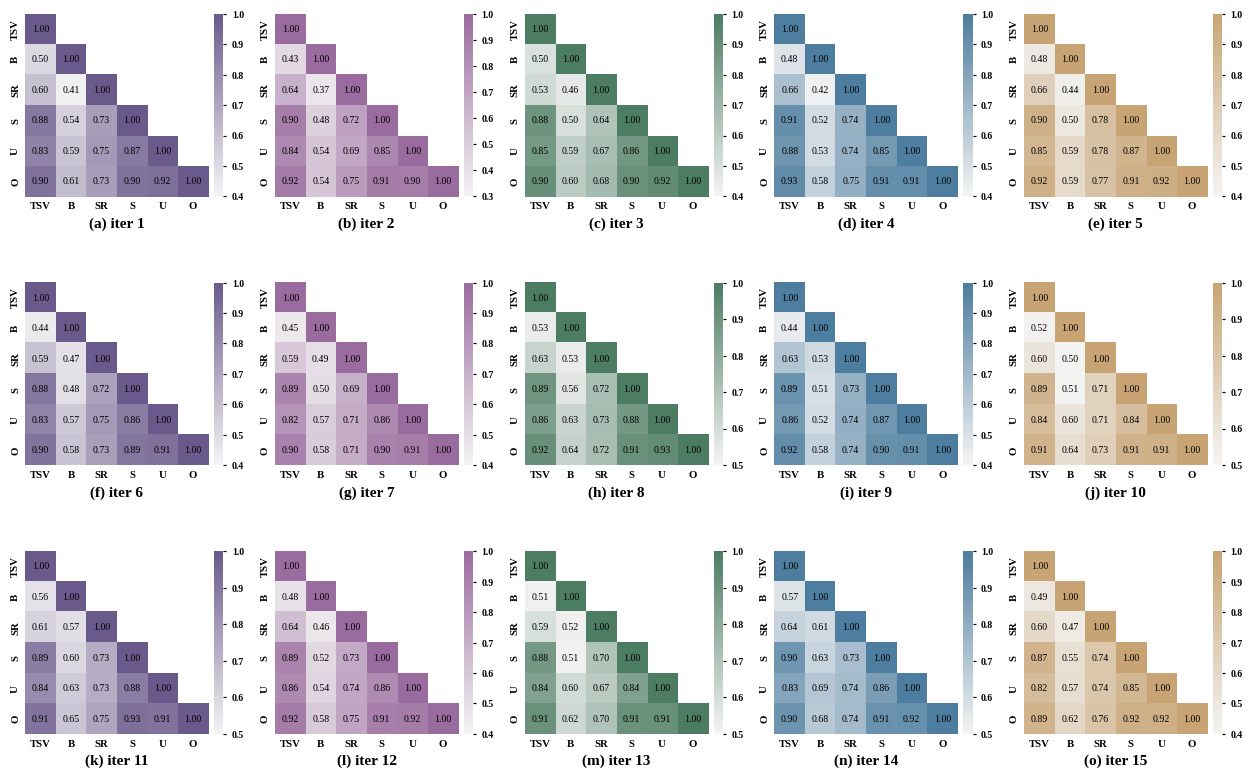

Mean |difference| between the prediction matrix and the MOS matrix (off-diagonal): 0.088 ± 0.020 over 15 iterations (small = the model reproduces the dependencies between attributes seen in the human ratings)


In [12]:
# ============ CELL 9 — DARNet Fig. 7 style: a grid of 15 correlation matrices (PLCC between the six quality dimensions) ============
# DARNet draws one matrix per SUBJECT (15 raters).  The subject-level ratings are not part of MOS.txt, so by default this cell draws the same grid for
#   (A) the model's PREDICTIONS on the test set of each of the first 15 iterations, and (B) the ground-truth MOS of the same test clips (so the two can be compared).
# If you have the per-subject ratings, set SUBJECT_RATINGS_FILE to a CSV with columns: subject, video_id, TSV, B, SR, S, U, O  -> the grid is then drawn exactly as in the paper (one matrix per subject).
SUBJECT_RATINGS_FILE = None            # e.g. "/kaggle/input/<dataset>/subject_ratings.csv"
N_PANELS = 15
from matplotlib.colors import LinearSegmentedColormap
COLS = ["#6A5A8C", "#9A6B9E", "#4C7C62", "#4D7D9F", "#C8A474"]          # purple, pink-purple, green, blue, tan: one colour per column of panels (as in Fig. 7)
def corr6(a):                                                            # a: [n,6] -> PLCC matrix in the order TSV,B,SR,S,U,O
    return np.corrcoef(a.T)
def matrix_grid(mats, name, titles=None):
    k = len(mats); fig, axs = plt.subplots(3, 5, figsize=(11.5, 7.6))
    for i, ax in enumerate(axs.ravel()):
        if i >= k: ax.axis("off"); continue
        C = mats[i]; col = COLS[i % 5]; cm = LinearSegmentedColormap.from_list("c", ["#F4F4F4", col]); cm.set_bad("white")
        off = C[np.tril_indices(6, -1)]; vmin = max(0.0, np.floor(off.min() * 10) / 10)
        im = ax.imshow(np.ma.masked_where(np.triu(np.ones((6, 6), bool), 1), C), cmap=cm, vmin=vmin, vmax=1.0)
        for r in range(6):
            for c in range(r + 1): ax.text(c, r, f"{C[r, c]:.2f}", ha="center", va="center", fontsize=6.5, color="black")
        ax.set_xticks(range(6)); ax.set_xticklabels(ORDER, fontsize=7); ax.set_yticks(range(6)); ax.set_yticklabels(ORDER, fontsize=7, rotation=90, va="center")
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.tick_params(length=0); ax.set_xlabel(f"({chr(97 + i)})" + (f" {titles[i]}" if titles else ""), fontsize=10)
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=6.5, length=2)
    fig.tight_layout(); save_fig(fig, name)

if SUBJECT_RATINGS_FILE and Path(SUBJECT_RATINGS_FILE).exists():
    sr = pd.read_csv(SUBJECT_RATINGS_FILE); subs = sorted(sr["subject"].unique())[:N_PANELS]
    mats = [corr6(sr[sr["subject"] == s][ORDER].values.astype(float)) for s in subs]
    pd.DataFrame(np.array(mats).reshape(len(mats), -1), index=subs).round(3).to_csv(TAB / "fig7_subject_matrices.csv")
    matrix_grid(mats, "fig7_subject_correlation_matrices")
else:
    its = seeds_done[:N_PANELS]
    mp = [corr6(PRED[s]["mapped"]) for s in its]                          # predictions (after the validation-fitted logistic mapping)
    mm = [corr6(PRED[s]["y"]) for s in its]                               # MOS of the same test clips
    matrix_grid(mp, "fig7_prediction_correlation_matrices_15_iterations", [f"iter {s + 1}" for s in its])
    matrix_grid(mm, "fig7_MOS_correlation_matrices_15_iterations", [f"iter {s + 1}" for s in its])
    iu = np.tril_indices(6, -1); gap = np.array([np.abs(a - b)[iu].mean() for a, b in zip(mp, mm)])
    pd.DataFrame({"iteration": [s + 1 for s in its], "mean_abs_difference_prediction_vs_MOS_matrix": gap.round(4)}).to_csv(TAB / "fig7_matrix_agreement.csv", index=False)
    print(f"Mean |difference| between the prediction matrix and the MOS matrix (off-diagonal): {gap.mean():.3f} ± {gap.std(ddof=1):.3f} over {len(its)} iterations "
          f"(small = the model reproduces the dependencies between attributes seen in the human ratings)")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


per-patient correlations (median over patients): TSV: PLCC 0.800, SRCC 0.707 | B: PLCC 0.737, SRCC 0.705 | SR: PLCC 0.783, SRCC 0.707 | S: PLCC 0.878, SRCC 0.798 | U: PLCC 0.839, SRCC 0.764 | O: PLCC 0.889, SRCC 0.815   (68 patients)
saved fig12b_boxplot_across_patients.eps / .png / .pdf  (600 dpi)


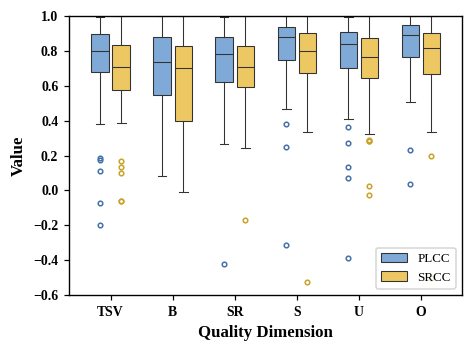

saved fig_extra_bland_altman.eps / .png / .pdf  (600 dpi)


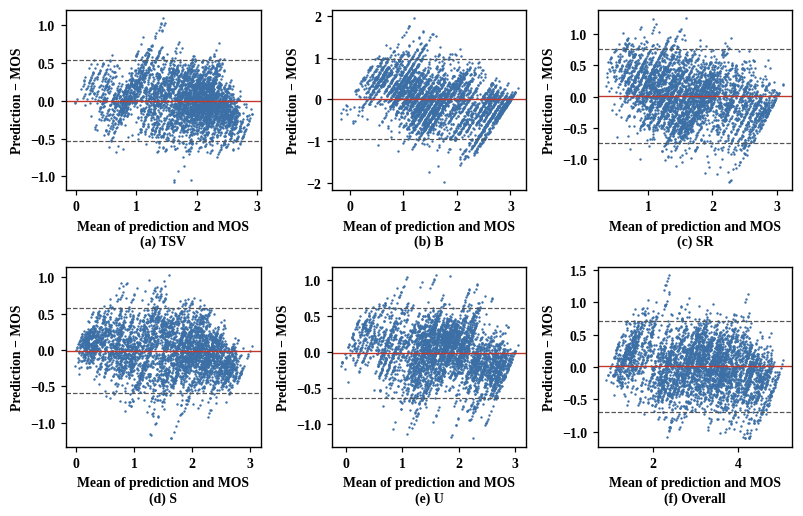

  score   bias    sd  lower_limit  upper_limit  pct_within_limits
    TSV  0.005 0.271       -0.527        0.537             95.275
      B  0.010 0.489       -0.948        0.969             94.625
     SR  0.011 0.384       -0.741        0.763             95.225
      S -0.010 0.297       -0.592        0.573             95.350
      U -0.018 0.318       -0.642        0.605             94.975
Overall  0.012 0.358       -0.689        0.714             95.150


In [17]:
# ============ CELL 10 — figures that do NOT need per-subject ratings: (1) box plots across PATIENTS per quality dimension, (2) Bland-Altman agreement plots ============
# (1) closest equivalent of DARNet Fig. 12: instead of one box per subject, one box per quality dimension, spread over the patients (PLCC / SRCC on each patient's test clips, mean over the iterations).
rowsP = []
for s in seeds_done:
    te_ = PRED[s]["te"]
    for u in np.unique(pat[te_]):
        m_ = pat[te_] == u
        if m_.sum() < 3: continue
        for t in ORDER:
            j = TARGETS.index(t); a, b = PRED[s]["y"][m_, j], PRED[s]["mapped"][m_, j]
            if np.std(a) > 1e-9 and np.std(b) > 1e-9: rowsP.append(dict(patient=u, dim=t, seed=s, PLCC=float(pearsonr(a, b)[0]), SRCC=float(spearmanr(a, b)[0])))
PD_ = pd.DataFrame(rowsP).groupby(["patient", "dim"])[["PLCC", "SRCC"]].mean().reset_index(); PD_.round(4).to_csv(TAB / "per_patient_all_dimensions.csv", index=False)
print("per-patient correlations (median over patients): " + " | ".join(f"{t}: PLCC {PD_[PD_.dim == t].PLCC.median():.3f}, SRCC {PD_[PD_.dim == t].SRCC.median():.3f}" for t in ORDER) + f"   ({PD_.patient.nunique()} patients)")
fig, ax = plt.subplots(figsize=(4.4, 3.3)); pos = np.arange(len(ORDER)); w = 0.34
fl = dict(marker="o", markersize=3, markerfacecolor="none", markeredgecolor="#4472A8")
b1 = ax.boxplot([PD_[PD_.dim == t].PLCC.values for t in ORDER], positions=pos - w / 2, widths=0.28, patch_artist=True, flierprops=fl)
b2 = ax.boxplot([PD_[PD_.dim == t].SRCC.values for t in ORDER], positions=pos + w / 2, widths=0.28, patch_artist=True, flierprops={**fl, "markeredgecolor": "#C9A227"})
for bp, c in ((b1, "#7FA9D6"), (b2, "#EDC862")):
    for b_ in bp["boxes"]: b_.set(facecolor=c, edgecolor="#333333", linewidth=0.7)
    for k in ("whiskers", "caps", "medians"):
        for e in bp[k]: e.set(color="#333333", linewidth=0.7)
ax.set_xticks(pos); ax.set_xticklabels(ORDER); ax.set_xlabel("Quality Dimension"); ax.set_ylabel("Value"); ax.set_ylim(min(0.5, np.floor(PD_[["PLCC", "SRCC"]].values.min() * 10) / 10), 1.0)
ax.legend([b1["boxes"][0], b2["boxes"][0]], ["PLCC", "SRCC"], loc="lower right", frameon=True); fig.tight_layout(); save_fig(fig, "fig12b_boxplot_across_patients")

# (2) Bland-Altman: x = mean of prediction and MOS, y = prediction - MOS, all test clips of all iterations pooled; lines = mean error and mean ± 1.96 SD
fig, axs = plt.subplots(2, 3, figsize=(7.4, 4.8)); BA = []
for k, (ax, t) in enumerate(zip(axs.ravel(), ORDER)):
    j = TARGETS.index(t); p = np.concatenate([PRED[s]["mapped"][:, j] for s in seeds_done]); y = np.concatenate([PRED[s]["y"][:, j] for s in seeds_done])
    mn, df = (p + y) / 2, p - y; bias, sd = df.mean(), df.std(ddof=1); BA.append(dict(score=NAME6[t], bias=bias, sd=sd, lower_limit=bias - 1.96 * sd, upper_limit=bias + 1.96 * sd, pct_within_limits=100 * np.mean(np.abs(df - bias) <= 1.96 * sd)))
    ax.scatter(mn, df, s=2.5, color=BLUE, linewidths=0); ax.axhline(bias, color="#C0392B", lw=0.9); ax.axhline(bias + 1.96 * sd, color="#555555", lw=0.8, ls="--"); ax.axhline(bias - 1.96 * sd, color="#555555", lw=0.8, ls="--")
    ax.set_xlabel(f"Mean of prediction and MOS\n({'abcdef'[k]}) {NAME6[t]}", fontsize=9); ax.set_ylabel("Prediction − MOS", fontsize=9)
fig.tight_layout(); save_fig(fig, "fig_extra_bland_altman"); pd.DataFrame(BA).round(4).to_csv(TAB / "bland_altman_summary.csv", index=False); print(pd.DataFrame(BA).round(3).to_string(index=False))

In [18]:
# ============ CELL 10 — zip everything ============
ZIP = WORK / "cvstqa_final_concat_20iter_results.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(OUT.parent))
print(f"Wrote {ZIP} ({ZIP.stat().st_size / 1e6:.1f} MB): runs.csv, tables, figures, per-run predictions, README_final_results.md")


Wrote /kaggle/working/cvstqa_final_concat_20iter_results.zip (7.8 MB): runs.csv, tables, figures, per-run predictions, README_final_results.md
